# Build a custom filter with Dynestyx

A custom filter plugs into the same `dsx.Filter` handler as a built-in filter. You supply two callbacks. `build_filter(model)` binds an algorithm to the current model, and `gather_outputs` selects what each observation contributes to the result. Dynestyx runs the time loop, constructs posterior distributions, and registers the likelihood when you call `dsx.sample`.

We'll implement the same Gauss–Hermite algorithm twice: once with split prediction and update callbacks, and once with Cuthbert’s combined callback. Both versions expose the innovation as a custom diagnostic. We check them against each other and an exact Kalman filter. We then estimate the angle and angular velocity of a swinging pendulum from noisy angle readings and compare the custom filter with the built-in UKF.

In [ ]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import numpy as np
import numpyro.distributions as dist
from numpyro.handlers import seed, trace
from cuthbert.inference import Filter as CuthbertFilter
from cuthbertlib.quadrature import gauss_hermite

import dynestyx as dsx
from dynestyx.configs import CustomFilterConfig, KFConfig, UKFConfig
from dynestyx.inference.custom_filter import FilterOutputs, SplitFilter
from dynestyx.inference.observation_predictions import PredictedObservationOutputs

## Decide what a step returns

The state is yours to design. This algorithm needs a filtered mean, covariance, and running log likelihood for the next step. It also carries the predictive observation moments and innovation so the gather callback can expose them. Keep the same field shapes at every step for JAX's scan.

In [ ]:
class Prior(NamedTuple):
    mean: jax.Array
    cov: jax.Array
    loglik: jax.Array  # Evidence accumulated through the previous observation.


class State(NamedTuple):
    mean: jax.Array
    cov: jax.Array
    loglik: jax.Array
    predictions: PredictedObservationOutputs
    innovation: jax.Array

In [ ]:
def gather_outputs(state):
    return FilterOutputs(
        log_normalizing_constant=state.loglik,
        filtered_means=state.mean,
        filtered_covariances=state.cov,
        predicted_observations=state.predictions,
        extra_outputs={"innovation": state.innovation},
    )

`FilterOutputs` is the boundary between your algorithm and Dynestyx. The Gaussian fields become one distribution per observation in `result.dists`. The last cumulative log likelihood becomes `result.marginal_loglik`, and named extras are stacked along observation time. Here the innovation is $y_k-\hat y_{k|k-1}$, so saving it also gives us a way to check that predictions were gathered before assimilation.

## Implement the split interface

The factory binds the model and quadrature rule once. At the first observation Dynestyx calls `initialize` and passes its prior straight to `update`. At later observations it calls `predict` and then `update`. The two-argument gather callback receives both the prior and the filtered state. Here the update already saved the innovation, so gathering needs only the filtered state.

In [ ]:
def build_split_filter(model):
    rule = gauss_hermite.weights(model.state_dim, order=3)

    def initialize(inputs, *, key):
        return initial_prior(model)

    def predict(filtered, inputs, *, key):
        return predict_prior(model, rule, filtered, inputs)

    def update(prior, inputs, *, key):
        return update_state(model, rule, prior, inputs)

    return SplitFilter(initialize=initialize, predict=predict, update=update)


def gather_split(prior, filtered):
    return gather_outputs(filtered)


split_config = CustomFilterConfig(build_filter=build_split_filter, gather_outputs=gather_split)

## Implement the combined interface

Cuthbert separates preparation from combination. `prepare` can package the current inputs before the previous belief is available. Here it just forwards them. `combine` owns the first-step decision and returns a complete filtered state. Its gather callback takes that state as its sole argument. Both factories use the same numerical helpers.

In [ ]:
def build_combined_filter(model):
    rule = gauss_hermite.weights(model.state_dim, order=3)

    def initialize(*, key):
        prior = initial_prior(model)
        # The initial scan carry has the same structure as every filtered state.
        zero = jnp.zeros(model.observation_dim, dtype=prior.mean.dtype)
        zeros = jnp.outer(zero, zero)
        predictions = PredictedObservationOutputs(mean=zero, cov=zeros, obs_cov=zeros)
        return State(prior.mean, prior.cov, prior.loglik, predictions, zero)

    def prepare(inputs, *, key):
        return inputs

    def combine(filtered, inputs):
        prior = jax.lax.cond(
            inputs.is_first_step,
            lambda: Prior(filtered.mean, filtered.cov, filtered.loglik),
            lambda: predict_prior(model, rule, filtered, inputs),
        )
        return update_state(model, rule, prior, inputs)

    return CuthbertFilter(init_prepare=initialize, filter_prepare=prepare,
                          filter_combine=combine, associative=False)


combined_config = CustomFilterConfig(build_filter=build_combined_filter,
                                     gather_outputs=gather_outputs)

## Share the numerical steps

This example uses order-three Gauss–Hermite quadrature. For a Gaussian input, `transform` evaluates the model at weighted points and returns four quantities: the output mean, the covariance of the signal, the average noise covariance, and the state–signal cross-covariance. `update_state` uses them for a Gaussian update and adds the predictive log density of this observation to the running total.

In [ ]:
def transform(rule, mean, cov, conditional):
    points = rule.get_sigma_points(mean, jnp.linalg.cholesky(cov))

    def moments(x):
        distribution = conditional(x)
        return distribution.mean, distribution.covariance_matrix

    means, covs = jax.vmap(moments)(points.points)
    signals = points._replace(points=means)
    noise = jnp.einsum("i,ijk->jk", points.wm, covs)
    return signals.mean, signals.covariance(), noise, points.covariance(signals)


def initial_prior(model):
    initial = model.initial_condition
    return Prior(initial.mean, initial.covariance_matrix, jnp.zeros_like(initial.mean[0]))


def predict_prior(model, rule, filtered, inputs):
    def transition(x):
        return model.state_evolution(x, inputs.u_prev, inputs.time_prev, inputs.time)

    mean, signal, noise, _ = transform(rule, filtered.mean, filtered.cov, transition)
    return Prior(mean, signal + noise, filtered.loglik)


def update_state(model, rule, prior, inputs):
    mean, cov, previous_loglik = prior
    y = inputs.y

    def observe(x):
        return model.observation_model(x, inputs.u, inputs.time)

    y_mean, signal, noise, cross = transform(rule, mean, cov, observe)
    y_cov = signal + noise
    gain = jnp.linalg.solve(y_cov, cross.T).T
    innovation = y - y_mean
    return State(
        mean=mean + gain @ innovation,
        cov=cov - gain @ cross.T,
        loglik=previous_loglik + dist.MultivariateNormal(y_mean, y_cov).log_prob(y),
        predictions=PredictedObservationOutputs(mean=y_mean, cov=signal, obs_cov=y_cov),
        innovation=innovation,
    )

## Estimate a pendulum's motion from angle readings

A sensor measures the pendulum angle every 0.15 s. Angular velocity is hidden. The model uses gravity and damping to relate the two coordinates, with process noise allowing the motion to depart from the deterministic swing. We simulate one trajectory with a fixed seed and keep its latent states for evaluation. Each filter receives only the measurement times and noisy angles.

In [ ]:
dt = 0.15  # seconds per observation
def pendulum_step(x, u, t, t_next):
    angle, velocity = x
    acceleration = -4.0 * jnp.sin(angle) - 0.18 * velocity
    next_velocity = velocity + dt * acceleration
    return jnp.array([angle + dt * next_velocity, next_velocity])


model = dsx.DynamicalModel(
    control_dim=0,
    initial_condition=dist.MultivariateNormal(
        jnp.array([1.4, 0.0]), jnp.diag(jnp.array([0.35, 0.6]) ** 2)
    ),
    state_evolution=dsx.GaussianStateEvolution(
        F=pendulum_step, cov=jnp.diag(jnp.array([0.025, 0.15]) ** 2)
    ),
    observation_model=dsx.LinearGaussianObservation(
        H=jnp.array([[1., 0.]]), R=jnp.array([[0.35**2]])
    ),
)
times = dt * jnp.arange(81)
initial_key, process_key, sensor_key = jax.random.split(jax.random.key(42), 3)
initial = model.initial_condition.sample(initial_key)

def advance(previous, step):
    t0, t1, key = step
    current = model.state_evolution(previous, None, t0, t1).sample(key)
    return current, current

_, path = jax.lax.scan(advance, initial,
                       (times[:-1], times[1:], jax.random.split(process_key, len(times) - 1)))
truth = jnp.concatenate([initial[None], path])
angles = jax.vmap(lambda x, t, k: model.observation_model(x, None, t).sample(k))(
    truth, times, jax.random.split(sensor_key, len(times))
)
data = dict(obs_times=times, obs_values=angles)
configs = {"Split": split_config, "Combined": combined_config}
results = {}
for name, config in configs.items():
    with dsx.Filter(config):
        results[name] = dsx.condition("x", model, **data)

split, combined = results["Split"], results["Combined"]
# Compare the entire gathered history, including covariances, diagnostics, and evidence.
assert jax.tree.structure(split.states) == jax.tree.structure(combined.states)
for left, right in zip(jax.tree.leaves(split.states), jax.tree.leaves(combined.states), strict=True):
    np.testing.assert_allclose(left, right, atol=1e-5)
np.testing.assert_allclose(split.extra_outputs["innovation"],
                           data["obs_values"] - split.predicted_observations.mean, atol=1e-5)
for name, result in results.items():
    print(name, "filtered mean at the final observation:", result.dists[-1].mean)

In [ ]:
for name, config in configs.items():
    with trace() as sites, seed(rng_seed=0), dsx.Filter(config):
        dsx.sample("x", model, **data)
    factor = sites["x_marginal_log_likelihood"]["fn"].log_factor
    np.testing.assert_allclose(factor, results[name].marginal_loglik, atol=1e-6)
    print(name, "log likelihood registered with NumPyro:", factor)

## Check the callback wiring on a linear model

Each factory can bind to a different model. On linear dynamics and observations, the quadrature moments are exact. Comparing every posterior and every cumulative likelihood with the Kalman filter checks initialization, time alignment, and the output mapping.

In [ ]:
linear_data = dict(obs_times=times[:4], obs_values=angles[:4])
linear = dsx.LTI_discrete(A=jnp.array([[0.8]]), Q=0.1*jnp.eye(1),
                          H=jnp.eye(1), R=0.2*jnp.eye(1))
with dsx.Filter(KFConfig(filter_source="cuthbert")):
    exact = dsx.condition("x", linear, **linear_data)
for config in configs.values():
    with dsx.Filter(config):
        gh = dsx.condition("x", linear, **linear_data)
    for a, b in zip(gh.dists, exact.dists, strict=True):
        np.testing.assert_allclose(a.mean, b.mean, atol=1e-5)
        np.testing.assert_allclose(a.covariance_matrix, b.covariance_matrix, atol=1e-5)
    np.testing.assert_allclose(gh.log_normalizing_constant, exact.log_normalizing_constant, atol=1e-5)
    np.testing.assert_allclose(gh.marginal_loglik, exact.marginal_loglik, atol=1e-5)

## Compare the filtered trajectories

Run the built-in UKF with the same prior, dynamics, and observations. The plot shows the posterior mean at each time using only the readings available through that time. The two Gauss–Hermite interfaces agree, so one column represents both. The shaded regions are pointwise 90% intervals from each filter’s Gaussian approximation.

Gauss–Hermite: angle RMSE 0.160 rad; angular velocity RMSE 0.301 rad/s
UKF: angle RMSE 0.160 rad; angular velocity RMSE 0.301 rad/s


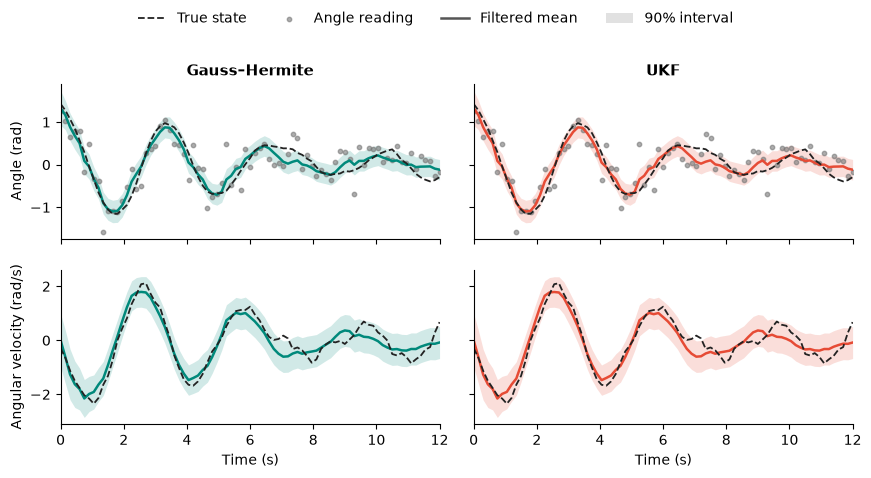

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import norm

with dsx.Filter(UKFConfig()):
    ukf = dsx.condition("x", model, **data)

methods = [("Gauss–Hermite", split, "#00897B"), ("UKF", ukf, "#E64B35")]
coordinates = ["Angle (rad)", "Angular velocity (rad/s)"]
fig, axes = plt.subplots(2, 2, figsize=(9, 4.8), sharex=True, sharey="row")
fig.subplots_adjust(left=0.10, right=0.98, bottom=0.12, top=0.83,
                    hspace=0.20, wspace=0.09)

for col, (method, result, color) in enumerate(methods):
    means = np.stack([belief.mean for belief in result.dists])
    std = np.sqrt(np.stack([belief.variance for belief in result.dists]))
    rmse = np.sqrt(np.mean((means - np.asarray(truth)) ** 2, axis=0))
    axes[0, col].set_title(method, fontsize=11, fontweight="bold")
    for k, ax in enumerate(axes[:, col]):
        half_width = norm.ppf(0.95) * std[:, k]
        band = ax.fill_between(times, means[:, k] - half_width, means[:, k] + half_width,
                               color=color, alpha=0.18, linewidth=0)
        if k == 0:
            observations = ax.scatter(times, angles[:, 0], s=10, color="#777777", alpha=0.6)
        estimate, = ax.plot(times, means[:, k], color=color, linewidth=1.8)
        latent, = ax.plot(times, truth[:, k], color="#222222", linestyle="--", linewidth=1.3)
        ax.set_xlim(times[0], times[-1])
        ax.spines[["right", "top"]].set_visible(False)
        if col == 0:
            ax.set_ylabel(coordinates[k])
    axes[1, col].set_xlabel("Time (s)")
    print(f"{method}: angle RMSE {rmse[0]:.3f} rad; angular velocity RMSE {rmse[1]:.3f} rad/s")

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig.legend([latent, observations, Line2D([], [], color="#555555", linewidth=1.8),
            Patch(facecolor="#888888", alpha=0.25)],
           ["True state", "Angle reading", "Filtered mean", "90% interval"],
           loc="upper center", ncol=4, frameon=False)
plt.show()

The two filters track the swing closely on this trajectory. Each has an angle RMSE of **0.160 rad** and an angular-velocity RMSE of **0.301 rad/s** to three decimal places. Near 8 s both estimates miss some of the change in angular velocity, even though the estimated angle follows the readings. The bottom row makes that error visible in the coordinate the sensor never observes.